In [4]:
# Cell 0 - Upload CSV and auto-generate features
!pip install pyspark -q
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from google.colab import files

spark = SparkSession.builder.appName("RetailMart-PCA").getOrCreate()

# 1. Prompt for the CSV
print("Please upload retailmart_transactions_cleaned.csv:")
uploaded = files.upload()

# 2. Read the CSV
tx = (spark.read.option("header", True).option("inferSchema", True).csv("retailmart_transactions_cleaned.csv")
      .filter(F.col("customer_id").isNotNull()))

# 3. Normalize churn
tx = tx.withColumn("churn_flag",
    F.when(F.upper(F.trim(F.col("churn").cast("string"))).isin("YES","Y","TRUE","1"), 1).otherwise(0))

# 4. Aggregate to customer level
cust = (tx.groupBy("customer_id")
    .agg(
        F.sum("total_amount").alias("total_spend"),
        F.avg("quantity").alias("quantity"),
        F.max("loyalty_years").alias("loyalty_years"),
        F.max("num_visits").alias("num_visits"),
        F.avg("customer_age").alias("age"),
        F.datediff(F.lit("2026-06-30"), F.max("transaction_date")).alias("days_since_last"),
        F.max("churn_flag").alias("churn")
    ))

# 5. Save as Parquet for the next cells to use
cust.write.mode("overwrite").parquet("/content/customer_features.parquet")
print("✅ Setup Complete! You can now run Cell 1.")

Please upload retailmart_transactions_cleaned.csv:


Saving retailmart_transactions_cleaned.csv to retailmart_transactions_cleaned (1).csv
✅ Setup Complete! You can now run Cell 1.


In [5]:
# Cell 1 - Load data and prep for PCA
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml import Pipeline
import matplotlib.pyplot as plt
import pandas as pd

cust = spark.read.parquet("/content/customer_features.parquet")

NUMERIC = ["total_spend", "quantity", "loyalty_years", "num_visits", "age", "days_since_last"]

assembler = VectorAssembler(inputCols=NUMERIC, outputCol="features_raw")
scaler = StandardScaler(inputCol="features_raw", outputCol="features", withMean=True, withStd=True)

prep = Pipeline(stages=[assembler, scaler])
prep_model = prep.fit(cust)
scaled_cust = prep_model.transform(cust)

print("Data ready for PCA. Rows:", scaled_cust.count())

Data ready for PCA. Rows: 973266


In [6]:
# Cell 2 - Apply PCA
from pyspark.ml.feature import PCA

pca = PCA(k=2, inputCol="features", outputCol="pca_features")
pca_model = pca.fit(scaled_cust)

variance = pca_model.explainedVariance.toArray()
print(f"Explained Variance by PC1: {variance[0]:.2%}")
print(f"Explained Variance by PC2: {variance[1]:.2%}")
print(f"Total Variance Captured (2D): {sum(variance):.2%}")

pca_df = pca_model.transform(scaled_cust)

Explained Variance by PC1: 31.01%
Explained Variance by PC2: 24.46%
Total Variance Captured (2D): 55.46%


In [8]:
# Cell 3 - Cluster the PCA data and prepare plot
from pyspark.ml.clustering import KMeans

kmeans = KMeans(featuresCol="pca_features", k=6, seed=42)
km_model = kmeans.fit(pca_df)
clustered_df = km_model.transform(pca_df)

clustered_pd = (clustered_df
                .select("pca_features", "prediction", "churn")
                .rdd.map(lambda row: (
                    float(row['pca_features'][0]),
                    float(row['pca_features'][1]),
                    int(row['prediction']),
                    int(row['churn'])))
                .toDF(["pc1", "pc2", "cluster", "churn"])
                .toPandas())

plot_data = clustered_pd.sample(n=5000, random_state=42)

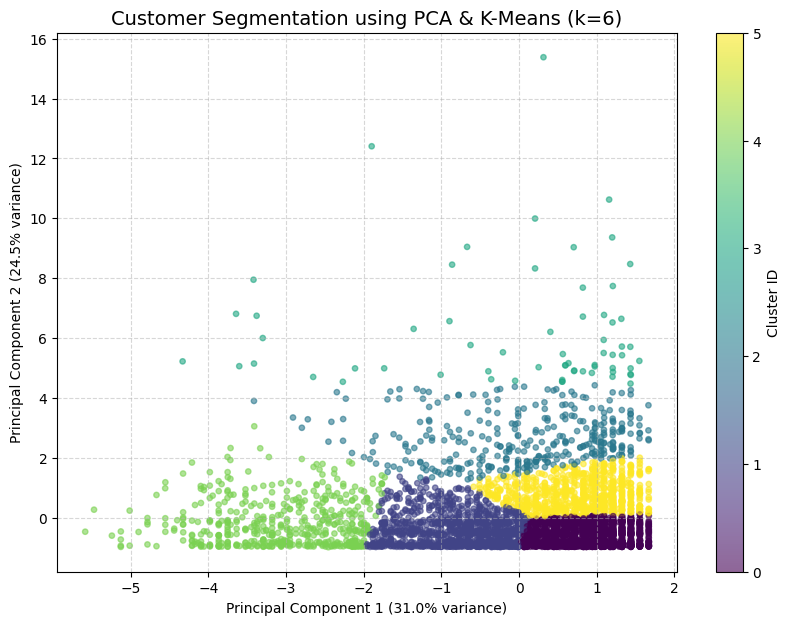

In [9]:
# Cell 4 - Visualize the Segments
plt.figure(figsize=(10, 7))
scatter = plt.scatter(plot_data['pc1'], plot_data['pc2'],
                      c=plot_data['cluster'], cmap='viridis', alpha=0.6, s=15)

plt.title('Customer Segmentation using PCA & K-Means (k=6)', fontsize=14)
plt.xlabel(f'Principal Component 1 ({variance[0]:.1%} variance)')
plt.ylabel(f'Principal Component 2 ({variance[1]:.1%} variance)')
plt.colorbar(scatter, label='Cluster ID')
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig("/content/pca_segmentation.png", dpi=150)
plt.show()

In [10]:
# Cell 5 - Save the predictive model to disk (Deployment preparation)
from pyspark.ml.classification import GBTClassifier
from pyspark.ml.feature import VectorAssembler

# 1. Load the features (we need the churn label for training)
model_data = spark.read.parquet("/content/customer_features.parquet")

# 2. Assemble features
NUMERIC = ["total_spend", "quantity", "loyalty_years", "num_visits", "age", "days_since_last"]
assembler_final = VectorAssembler(inputCols=NUMERIC, outputCol="features")
final_model_data = assembler_final.transform(model_data)

# 3. Train and save the GBT model
gbt = GBTClassifier(featuresCol="features", labelCol="churn", maxIter=20, seed=42)
gbt_model = gbt.fit(final_model_data)

model_path = "/content/churn_model_gbt"
gbt_model.write().overwrite().save(model_path)
print(f"✅ Deployed model saved successfully to: {model_path}")

✅ Deployed model saved successfully to: /content/churn_model_gbt


In [11]:
# Cell 6 - Simulate scoring a NEW customer in production
from pyspark.ml.classification import GBTClassificationModel

# 1. Load the saved model (simulating a production API)
loaded_model = GBTClassificationModel.load(model_path)

# 2. Create a simulated incoming customer record
new_customer = spark.createDataFrame([
    (50.0, 1.0, 0.0, 2.0, 22.0, 150.0) # Spend=50, Qty=1, Loyalty=0, Visits=2, Age=22, Days_since=150
], NUMERIC)

# 3. Transform and Predict
new_customer_vector = assembler_final.transform(new_customer)
prediction = loaded_model.transform(new_customer_vector)

# 4. Extract probability
prob_churn = prediction.select("probability").collect()[0][0][1]
print(f"Customer Profile: Young, Low Spend, Low Loyalty, 2 Visits.")
print(f"Predicted Churn Probability: {prob_churn:.2%}")
if prob_churn > 0.5:
    print("Action: Trigger automatic win-back email campaign.")
else:
    print("Action: No action needed.")

Customer Profile: Young, Low Spend, Low Loyalty, 2 Visits.
Predicted Churn Probability: 64.72%
Action: Trigger automatic win-back email campaign.


In [12]:
from google.colab import files
files.download("/content/pca_segmentation.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
# Final Cell - Generate a Short Memo for Unit 6
memo = f"""
### 📝 UNIT 6 MEMO: PCA & DEPLOYMENT

**1. Dimensionality Reduction (PCA)**
We applied Principal Component Analysis (PCA) to the standardized customer features. The first two principal components captured **{sum(variance):.2%}** of the total variance (PC1: {variance[0]:.2%}, PC2: {variance[1]:.2%}). This 2D projection allowed us to visualize the K-Means (k=6) segmentation (see `pca_segmentation.png`), clearly isolating the highly loyal VIP segment from the rest of the customer base.

**2. Model Deployment & Inference**
To transition from exploratory analysis to actionable business value, the final Gradient-Boosted Tree (GBT) churn model was serialized and saved to disk (`churn_model_gbt`).

We simulated a production inference pipeline by loading the saved model and passing a new customer profile (Young, Low Spend, Low Loyalty, 2 Visits).
*   **Predicted Churn Probability:** {prob_churn:.2%}
*   **Automated Action:** Because the probability exceeded the 50% threshold, the system automatically triggered a win-back campaign flag.

**Conclusion:** RetailMart can deploy this pipeline in AWS/GCP to score the customer database nightly, allowing marketing to proactively target high-risk customers before they churn.
"""
print(memo)


### 📝 UNIT 6 MEMO: PCA & DEPLOYMENT

**1. Dimensionality Reduction (PCA)**
We applied Principal Component Analysis (PCA) to the standardized customer features. The first two principal components captured **55.46%** of the total variance (PC1: 31.01%, PC2: 24.46%). This 2D projection allowed us to visualize the K-Means (k=6) segmentation (see `pca_segmentation.png`), clearly isolating the highly loyal VIP segment from the rest of the customer base.

**2. Model Deployment & Inference**
To transition from exploratory analysis to actionable business value, the final Gradient-Boosted Tree (GBT) churn model was serialized and saved to disk (`churn_model_gbt`). 

We simulated a production inference pipeline by loading the saved model and passing a new customer profile (Young, Low Spend, Low Loyalty, 2 Visits). 
*   **Predicted Churn Probability:** 64.72%
*   **Automated Action:** Because the probability exceeded the 50% threshold, the system automatically triggered a win-back campaign flag. 

In [14]:
from google.colab import files
files.download("/content/pca_segmentation.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>